# 0. Basics: Boolean circuits, truth tables, and the model

This notebook introduces the objects used in the paper, assuming no background in logic
design. Part 1 builds up Boolean circuits from single gates and shows how a circuit, its token
sequence and its truth table relate. Part 2 opens the trained model: its components, their
sizes, the strided positional encoding, and how it produces a circuit one token at a time.
The next notebook (`demo.ipynb`) runs the model and the outer loop on test circuits.

In [1]:
import sys
sys.path.insert(0, '..')   # run from notebooks/: make the llrg package importable
import numpy as np
from IPython.display import display, Image

from llrg import circuit as C
from llrg.vocab import TOKENS, DISPLAY, tokenize
from llrg.viz import show_tables


def table_text(outputs, n, names=None):
    """Print the truth table of a circuit as text: one row per input combination."""
    Y = C.evaluate(outputs, n)
    names = names or [f'y{j}' for j in range(Y.shape[1])]
    head = ' '.join(f'x{i}' for i in range(n)) + ' | ' + ' '.join(names)
    print(head); print('-' * len(head))
    for x, y in zip(C.input_table(n), Y):
        print('  '.join(map(str, x)) + '  | ' + '   '.join(map(str, y)))
    return Y

## Part 1. Boolean circuits

### 1.1 Four gates

A *Boolean function* maps input bits (0 or 1) to output bits. A *gate* is an elementary
Boolean function. We use four:

| gate | output is 1 when | token |
|---|---|---|
| AND | all inputs are 1 | `∧` |
| OR | at least one input is 1 | `∨` |
| XOR | an odd number of inputs are 1 | `⊻` |
| NOT | its single input is 0 | `~` |

Below, each gate is drawn with its standard symbol, followed by its truth table: the list of
outputs for every combination of inputs.

==== AND: tokens  0 ∧ 1


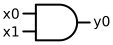

x0 x1 | y0
----------
0  0  | 0
0  1  | 0
1  0  | 0
1  1  | 1

==== OR: tokens  0 ∨ 1


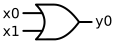

x0 x1 | y0
----------
0  0  | 0
0  1  | 1
1  0  | 1
1  1  | 1

==== XOR: tokens  0 ⊻ 1


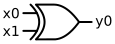

x0 x1 | y0
----------
0  0  | 0
0  1  | 1
1  0  | 1
1  1  | 0

==== NOT: tokens  ~ 0


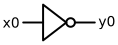

x0 | y0
-------
0  | 1
1  | 0


In [2]:
for name, text in [('AND', '0 ∧ 1'), ('OR', '0 ∨ 1'), ('XOR', '0 ⊻ 1')]:
    print(f'==== {name}: tokens  {text}')
    outs = C.parse(text)
    for d in C.draw(outs):
        display(d)
    table_text(outs, 2)
    print()

print('==== NOT: tokens  ~ 0')
outs = C.parse('~ 0')
for d in C.draw(outs):
    display(d)
table_text(outs, 1);

### 1.2 From gates to a circuit

A *circuit* connects gates: inputs feed gates, and gate outputs feed further gates. The circuit
computes a function of its inputs, which we can tabulate for all $2^n$ input combinations.

The rows of a truth table are always listed in the same order: as binary numbers with `x0` as
the most significant bit (`000`, `001`, `010`, ...). The circuit below has three inputs and
two levels of gates.

y0 = (x0 AND x1) OR NOT x2


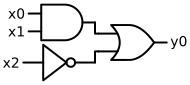

x0 x1 x2 | y0
-------------
0  0  0  | 1
0  0  1  | 0
0  1  0  | 1
0  1  1  | 0
1  0  0  | 1
1  0  1  | 0
1  1  0  | 1
1  1  1  | 1


In [3]:
outs = C.parse('( 0 ∧ 1 ) ∨ ( ~ 2 )')
print('y0 =', C.pretty(outs[0]))
for d in C.draw(outs):
    display(d)
Y = table_text(outs, 3)

To evaluate it by hand on one row, say `x0=1, x1=0, x2=0`: the AND gate gives `1 AND 0 = 0`, the NOT
gate gives `NOT 0 = 1`, and the OR gate gives `0 OR 1 = 1`. That is the value in the row `1 0 0`
of the table.

The **depth** of a circuit is the number of gate levels on its longest path from an input to
an output (here 2), and its **size** is the number of two-input gates and NOT gates (here 3).

In [4]:
print(C.stats(outs))

{'outputs': 1, 'gates': 3, 'depth': 2}


### 1.3 Circuits with several outputs

A circuit can compute several functions of the same inputs at once; its truth table then has
one column per output. Four classical examples follow, each shown as a drawing, as the token
sequence the model reads and writes, and as a truth table (shaded cells are 1).

==== half adder: y0 = sum, y1 = carry of x0 + x1
tokens: 0 ⊻ 1  <next output>  0 ∧ 1
  y0 = x0 XOR x1
  y1 = x0 AND x1


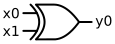

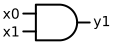

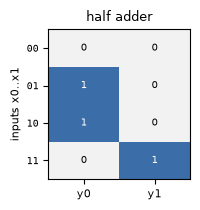

==== majority of three
tokens: ( 0 ∧ 1 ) ∨ ( 0 ∧ 2 ) ∨ ( 1 ∧ 2 )
  y0 = (x0 AND x1) OR (x0 AND x2) OR (x1 AND x2)


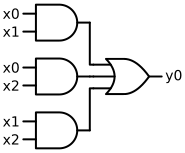

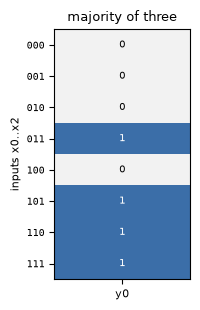

==== multiplexer: y0 = x1 if x0 = 0, else x2
tokens: ( 1 ∧ ~ 0 ) ∨ ( 0 ∧ 2 )
  y0 = (x1 AND NOT x0) OR (x0 AND x2)


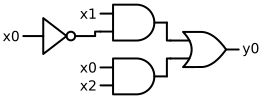

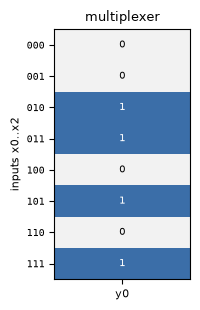

==== parity of three inputs
tokens: 0 ⊻ 1 ⊻ 2
  y0 = x0 XOR x1 XOR x2


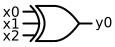

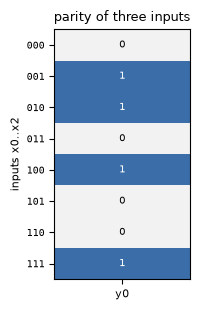

In [5]:
examples = {
    'half adder: y0 = sum, y1 = carry of x0 + x1': ('0 ⊻ 1\n0 ∧ 1', 2),
    'majority of three': ('( 0 ∧ 1 ) ∨ ( 0 ∧ 2 ) ∨ ( 1 ∧ 2 )', 3),
    'multiplexer: y0 = x1 if x0 = 0, else x2': ('( 1 ∧ ~ 0 ) ∨ ( 0 ∧ 2 )', 3),
    'parity of three inputs': ('0 ⊻ 1 ⊻ 2', 3),
}
for title, (text, n) in examples.items():
    print('====', title)
    outs = C.parse(text)
    print('tokens:', text.replace('\n', '  <next output>  '))
    for j, o in enumerate(outs):
        print(f'  y{j} = {C.pretty(o)}')
    for d in C.draw(outs):
        display(d)
    show_tables([C.evaluate(outs, n)], [title.split(':')[0]], n)

### 1.4 The token language

The model reads and writes circuits as sequences of tokens from a 16-token vocabulary:

* `<start>`, `<end>`: beginning and end of a circuit,
* `0` ... `4`: inputs `x0` ... `x4` (the model handles up to 5 inputs),
* `∧`, `∨`, `⊻`: AND, OR, XOR (they can take two or more operands),
* `~`: NOT, written before its operand,
* `ZERO`, `ONE`: constants,
* `(`, `)`: grouping,
* a newline token separating the outputs.

Parentheses group operands, and a gate symbol is never mixed with a different gate symbol at
the same level without parentheses, so the reading of a sequence is unambiguous.

In [6]:
print(f'{"id":>3}  {"token":8s} meaning')
for i, t in enumerate(TOKENS):
    print(f'{i:>3}  {repr(t):8s} {DISPLAY[t]}')

 id  token    meaning
  0  '<start>' <start>
  1  '<end>'  <end>
  2  '∧'      AND
  3  '∨'      OR
  4  '⊻'      XOR
  5  '~'      NOT
  6  'ZERO'   0
  7  'ONE'    1
  8  '('      (
  9  ')'      )
 10  '\n'     <next output>
 11  '0'      x0
 12  '1'      x1
 13  '2'      x2
 14  '3'      x3
 15  '4'      x4


In [7]:
text = '( 0 ⊻ 1 ) ∧ ~ 2\n0 ∨ 2'
ids = tokenize(text)
print('circuit text :', text.replace('\n', ' | '))
print('token ids    :', ids)
print('tokens       :', ' '.join(DISPLAY[TOKENS[i]] for i in ids))
outs = C.parse(ids)                      # token ids -> one expression tree per output
print('parsed trees :', outs)
print('back to text :', C.circuit_to_string(outs).replace('\n', ' | '))

circuit text : ( 0 ⊻ 1 ) ∧ ~ 2 | 0 ∨ 2
token ids    : [0, 8, 11, 4, 12, 9, 2, 5, 13, 10, 11, 3, 13, 1]
tokens       : <start> ( x0 XOR x1 ) AND NOT x2 <next output> x0 OR x2 <end>
parsed trees : [('AND', [('XOR', [('VAR', 0), ('VAR', 1)]), ('NOT', ('VAR', 2))]), ('OR', [('VAR', 0), ('VAR', 2)])]
back to text : ( 0 ⊻ 1 ) ∧ ~ 2 | 0 ∨ 2


### 1.5 One function, many circuits

Different circuits can compute the same function. XOR, for instance, can be built from AND, OR
and NOT gates instead of a single XOR gate. Both circuits below have the same truth table but
different sizes and depths. This is why *circuit synthesis* (finding a circuit for a given truth
table) has many correct answers, and why the model is judged by whether its circuit computes
the right table, not by whether it reproduces a particular circuit.

==== single XOR gate {'outputs': 1, 'gates': 1, 'depth': 1}


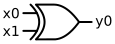

==== AND / OR / NOT {'outputs': 1, 'gates': 5, 'depth': 3}


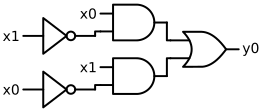

same truth table: True


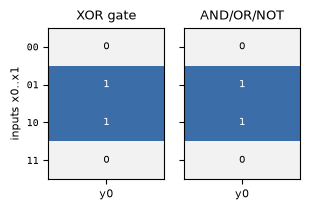

In [8]:
a = C.parse('0 ⊻ 1')
b = C.parse('( 0 ∧ ~ 1 ) ∨ ( 1 ∧ ~ 0 )')
for name, outs in [('single XOR gate', a), ('AND / OR / NOT', b)]:
    print('====', name, C.stats(outs))
    for d in C.draw(outs):
        display(d)
print('same truth table:', bool((C.evaluate(a, 2) == C.evaluate(b, 2)).all()))
show_tables([C.evaluate(a, 2), C.evaluate(b, 2)], ['XOR gate', 'AND/OR/NOT'], 2)

The number of Boolean functions grows very fast: with $n$ inputs and $m$ outputs there are
$2^{m \cdot 2^n}$ of them, about $10^{19}$ for $n = m = 4$ and $10^{48}$ for $n = m = 5$. A model
cannot memorize them; it has to learn how truth tables relate to circuits.

In [9]:
for n, m in [(2, 1), (3, 2), (4, 4), (5, 5)]:
    bits = m * 2 ** n
    print(f'n={n}, m={m}: 2^{bits} = {2 ** bits:.3e} functions')

n=2, m=1: 2^4 = 1.600e+01 functions
n=3, m=2: 2^16 = 6.554e+04 functions
n=4, m=4: 2^64 = 1.845e+19 functions
n=5, m=5: 2^160 = 1.462e+48 functions


## Part 2. The model

### 2.1 Overview

The model takes a truth table and writes a circuit for it, token by token.

* **Encoder.** Each cell of the truth table (one output bit for one input row) becomes a vector:
  a learned embedding of the bit (0 or 1) plus a learned embedding of the cell's position, then a
  linear projection. There is no self-attention in the encoder. The input columns are not given:
  they are implicit in the row order.
* **Decoder.** A GPT-2 style Transformer that generates the circuit tokens from left to right.
  At each step it attends to the tokens generated so far (self-attention) and to the encoded
  truth table (cross-attention).

The model was trained on circuits of depth at most 2, on all table shapes with 2 to 5 inputs and
1 to 5 outputs.

In [10]:
import json
import torch
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()   # silence a generic padding warning that does not apply here
from llrg import CircuitSynthesizer

model = CircuitSynthesizer.from_pretrained('../weights')
cfg = json.load(open('../weights/config.json'))
print(json.dumps(cfg, indent=1))

{
 "architecture": {
  "n_max": 5,
  "m_max": 5,
  "d_b": 64,
  "d": 128,
  "layers": 8,
  "heads": 4,
  "max_len": 512
 },
 "training": {
  "data": "reduced random circuits of depth <= 2, all shapes n in 2..5, m in 1..5, 1M circuits per shape",
  "optimizer": "AdamW lr 1e-4, batch 64, linear warmup (1 epoch) + cosine decay, 2 epochs"
 },
 "parameters": 2198016
}


### 2.2 Components and their sizes

In [11]:
groups = {}
for name, p in model.named_parameters():
    if name.startswith('encoder.bit_embedding'):
        g = 'encoder: bit embedding (2 x d_b)'
    elif name.startswith('encoder.position_embedding'):
        g = 'encoder: strided position embedding (160 x d_b)'
    elif name.startswith('encoder.projection'):
        g = 'encoder: projection d_b -> d'
    elif '.wte.' in name:
        g = 'decoder: token embedding (16 x d), shared with output layer'
    elif '.wpe.' in name:
        g = 'decoder: token position embedding (512 x d)'
    elif 'crossattention' in name or 'ln_cross_attn' in name:
        g = 'decoder blocks: cross-attention (to the truth table)'
    elif '.attn.' in name or '.ln_1.' in name:
        g = 'decoder blocks: self-attention'
    elif '.mlp.' in name or '.ln_2.' in name:
        g = 'decoder blocks: feed-forward (MLP)'
    else:
        g = 'decoder: final layer norm and other'
    groups[g] = groups.get(g, 0) + p.numel()
total = sum(groups.values())
for g, k in groups.items():
    print(f'{k:>10,}  {100 * k / total:5.1f}%  {g}')
print(f'{total:>10,}  total')
dec = model.decoder.config
print(f'\ndecoder: {dec.n_layer} blocks, {dec.n_head} heads, width d = {dec.n_embd}, '
      f'context window = {dec.n_positions} tokens, vocabulary = {dec.vocab_size} tokens')

       128    0.0%  encoder: bit embedding (2 x d_b)
    10,240    0.5%  encoder: strided position embedding (160 x d_b)
     8,320    0.4%  encoder: projection d_b -> d
     2,048    0.1%  decoder: token embedding (16 x d), shared with output layer
    65,536    3.0%  decoder: token position embedding (512 x d)
   530,432   24.1%  decoder blocks: self-attention
 1,055,744   47.9%  decoder blocks: feed-forward (MLP)
   530,432   24.1%  decoder blocks: cross-attention (to the truth table)
       256    0.0%  decoder: final layer norm and other
 2,203,136  total

decoder: 8 blocks, 4 heads, width d = 128, context window = 512 tokens, vocabulary = 16 tokens


Almost all parameters are in the decoder. The encoder is tiny: it only has to turn each bit of
the table into a vector that says *which* cell it is and *what* its value is.

### 2.3 Strided positional encoding

The encoder sees the table as a flat sequence of cells. Each cell needs a position index, and a
single model has to handle tables of many shapes. A naive index (0, 1, 2, ... in reading order)
would give the same cell different indices depending on the number of outputs of the table.
Instead, the cell in row $r$ and output column $j$ gets the index

$$\mathrm{strd}(r, j) = r \cdot m_{\max} + j,$$

where $m_{\max}$ is the largest number of outputs the model supports ($m_{\max} = 5$ here; the
figure from the paper uses 3 for readability). The index of a cell then does not depend on the
number of outputs of the table, nor on its number of inputs, since a table with fewer inputs
occupies the leading rows.

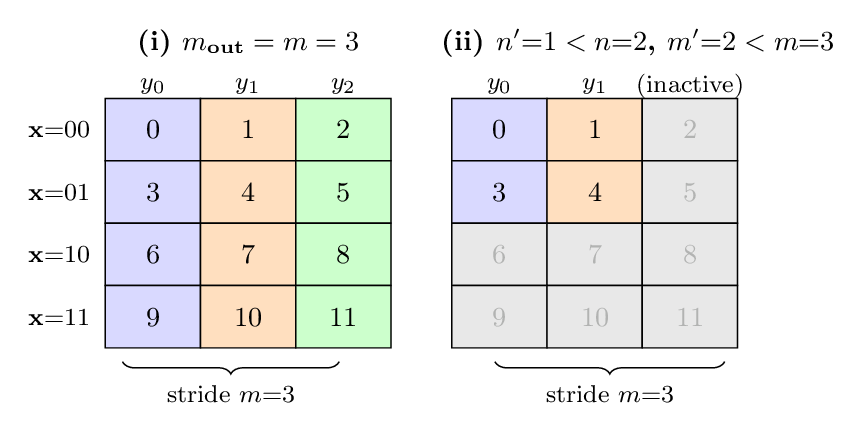

In [12]:
display(Image('../assets/strided_pe.png', width=520))

The implementation is two lines (from `llrg/model.py`):

In [13]:
import inspect
from llrg.model import strided_positions, TruthTableEncoder
print(inspect.getsource(strided_positions))
print(inspect.getsource(TruthTableEncoder.forward))

def strided_positions(R, m_max, m):
    """Position index r * m_max + j of every cell (row r, column j) of an R x m table."""
    return (torch.arange(R).view(R, 1) * m_max + torch.arange(m).view(1, m)).flatten()

    def forward(self, Y):
        """Y: (B, R, m) tensor of 0/1. Returns (B, R*m, d)."""
        B, R, m = Y.shape
        seq = Y.long().reshape(B, R * m)
        pos = self.positions(R, m).to(Y.device).unsqueeze(0).expand(B, -1)
        return self.projection(self.bit_embedding(seq) + self.position_embedding(pos))



The index grids for a few table shapes (rows = input combinations, columns = outputs): cell
`(r, j)` has the same index in every grid where it exists.

In [14]:
for n, m in [(2, 3), (2, 2), (1, 2), (3, 1)]:
    grid = strided_positions(2 ** n, 5, m).view(2 ** n, m)
    print(f'n={n} inputs, m={m} outputs:')
    print(grid.numpy(), '\n')

n=2 inputs, m=3 outputs:
[[ 0  1  2]
 [ 5  6  7]
 [10 11 12]
 [15 16 17]] 

n=2 inputs, m=2 outputs:
[[ 0  1]
 [ 5  6]
 [10 11]
 [15 16]] 

n=1 inputs, m=2 outputs:
[[0 1]
 [5 6]] 

n=3 inputs, m=1 outputs:
[[ 0]
 [ 5]
 [10]
 [15]
 [20]
 [25]
 [30]
 [35]] 



For a full-size table (5 inputs, 5 outputs) there are $32 \times 5 = 160$ cells, which is the
size of the position embedding table. A table with 4 inputs and 4 outputs uses 64 of the 160
positions.

### 2.4 Writing a circuit, one token at a time

The decoder produces the circuit autoregressively: at each step it outputs a probability for
each of the 16 tokens, the most likely one is appended, and the process repeats until `<end>`.
Here is that process on the half adder, with the three most likely tokens at each step.

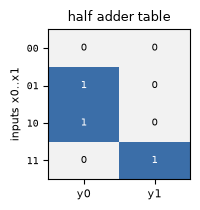

encoded table: (1, 8, 128) (batch, cells, d)
step  0:              ( 0.644               x0 0.236              NOT 0.120
step  1:             x0 1.000                ( 0.000              NOT 0.000
step  2:            AND 0.594               OR 0.405              XOR 0.000
step  3:             x1 1.000                ( 0.000              NOT 0.000
step  4:              ) 1.000    <next output> 0.000                1 0.000
step  5:            XOR 1.000               OR 0.000                1 0.000
step  6:              ( 1.000               x1 0.000               x0 0.000
step  7:             x0 1.000    <next output> 0.000                0 0.000
step  8:             OR 1.000              AND 0.000              NOT 0.000
step  9:             x1 1.000               x0 0.000                0 0.000


step 10:              ) 1.000    <next output> 0.000               x1 0.000


step 11:  <next output> 1.000               OR 0.000            <end> 0.000


step 12:              ( 0.747               x0 0.253              NOT 0.000
step 13:             x0 1.000                ( 0.000                0 0.000
step 14:             OR 0.596              AND 0.404              XOR 0.000


step 15:             x1 1.000                ( 0.000               x2 0.000
step 16:              ) 1.000            <end> 0.000               x1 0.000
step 17:            XOR 1.000              AND 0.000               x2 0.000
step 18:              ( 1.000                1 0.000                0 0.000
step 19:             x0 1.000                0 0.000               x1 0.000
step 20:            XOR 1.000               x1 0.000              AND 0.000
step 21:             x1 1.000                ) 0.000               x2 0.000
step 22:              ) 1.000            <end> 0.000               x1 0.000


step 23:          <end> 1.000    <next output> 0.000                ) 0.000

generated circuit:
  y0 = (x0 AND x1) XOR (x0 OR x1)
  y1 = (x0 OR x1) XOR (x0 XOR x1)
computes the table: True


In [15]:
Y = C.evaluate(C.parse('0 ⊻ 1\n0 ∧ 1'), 2)
show_tables([Y], ['half adder table'], 2)

with torch.no_grad():
    enc = model.encoder(torch.tensor(Y).unsqueeze(0))
    print('encoded table:', tuple(enc.shape), '(batch, cells, d)')
    ids = [0]
    for step in range(model.max_len - 1):
        logits = model.decoder(input_ids=torch.tensor([ids]), encoder_hidden_states=enc).logits[0, -1]
        probs = torch.softmax(logits, -1)
        top = torch.topk(probs, 3)
        nxt = int(top.indices[0])
        print(f'step {step:2d}: ' + '   '.join(f'{DISPLAY[TOKENS[int(i)]]:>14s} {float(p):.3f}'
                                            for p, i in zip(top.values, top.indices)))
        ids.append(nxt)
        if TOKENS[nxt] == '<end>':
            break

outs = C.parse(ids)
print('\ngenerated circuit:')
for j, o in enumerate(outs):
    print(f'  y{j} = {C.pretty(o)}')
print('computes the table:', bool((C.evaluate(outs, 2) == Y).all()))

Most steps are nearly certain; the few uncertain ones are choices between equivalent ways of
writing a gate's operands. Note also that the circuit the model wrote is not the textbook half
adder: for the sum it may write, for instance, `(x0 AND x1) XOR (x0 OR x1)`, which is equal to
`x0 XOR x1` on every input. As in section 1.5, any circuit with the right truth table is a
correct answer.

The next notebook, `demo.ipynb`, applies the model to circuits deeper than any it was trained
on, and shows how the outer loop corrects its errors.